In [1]:
import pickle 
import numpy as np
from tensorflow.keras.utils import to_categorical
from keras.preprocessing.sequence import pad_sequences
from keras.models import Model, Sequential
from keras.layers import Input
import matplotlib.pyplot as plt
from glob import glob
import os
from tensorflow.keras.applications import Xception
import tensorflow as tf
from glob import glob
import json
import cv2
import json
from nltk.translate.bleu_score import sentence_bleu, corpus_bleu

In [2]:

os.environ["CUDA_DEVICE_ORDER"] = "PCI_BUS_ID"
os.environ['CUDA_VISIBLE_DEVICES'] = '-1'

In [3]:
feature_model = Xception(include_top=True)

extractor = Model(inputs = feature_model.input,outputs = feature_model.layers[-2].output)
model = tf.keras.models.load_model('../Logs/Xception_BNG9k/logs/caption_model_RMSprop_BidirectionalLstm_512_256_512_24.06.2021-22_45/caption_model_RMSprop_BidirectionalLstm_512_256_512_24.06.2021-22_45.hdf5')


In [8]:
with open('../Data/BNG_9k/inv_dict.json') as f:
    inv_dict = json.load(f)


with open('../Data/BNG_9k/word_count.json') as f:
    word_count = json.load(f)
    
with open("../Data/BNG_9k/captions_dict.json") as f:
    captions_dict = json.loads(f.read())

In [5]:

images_path = '../Data/BNG_9k/images/'
images = glob(images_path+'*.png')
images[0]

'../Data/BNG_9k/images\\1.png'

In [6]:
with open('../Data/BNG_9k/inv_dict.json') as f:
    inv_dict = json.load(f)


with open('../Data/BNG_9k/word_count.json') as f:
    word_count = json.load(f)
    
with open("../Data/BNG_9k/captions_dict.json") as f:
    captions_dict = json.loads(f.read())

In [7]:
def getImage(x):
    
    test_img_path = images[x]

    test_img = cv2.imread(test_img_path)
    test_img = cv2.cvtColor(test_img, cv2.COLOR_BGR2RGB)

    test_img = cv2.resize(test_img, (299,299))

    test_img = np.reshape(test_img, (1,299,299,3))
    
    return test_img

In [8]:
embedded_caption = []
for image_name, text in captions_dict.items():
    embedded_caption.append([str(word_count[i]) for i in text[0].split()])

In [9]:
embedded_caption2 = []
for lst in embedded_caption:
    for each in lst:
        embedded_caption2.append(each)

In [10]:
MAX_LEN=39
content = []

In [11]:
for m in range(2):
    

    test_feature = extractor.predict(getImage(m)).reshape(1,2048)
    
    test_img_path = images[m]
    test_img = cv2.imread(test_img_path)
    test_img = cv2.cvtColor(test_img, cv2.COLOR_BGR2RGB)

    text_inp = ['startofseq']

    count = 0
    caption = ''
    while count < 25:
        count += 1

        encoded = []
        for i in text_inp:
            encoded.append(word_count[i])

        encoded = [encoded]
        encoded = pad_sequences(encoded, padding='post', truncating='post', maxlen=MAX_LEN)


        prediction = np.argmax(model.predict([test_feature, encoded]))
        sampled_word = inv_dict[str(prediction)]  
            
        if sampled_word == 'endofseq':
            break
        else:
            caption = caption + ' ' + sampled_word

        text_inp.append(sampled_word)
       
    content.append(caption)

In [12]:
contents =[i.strip() for i in content]
# contents

In [13]:
contents

['একটি হলুদ জামা পায়জামা পরা মহিলা দাড়িয়ে হাতে একটি বেত নিয়ে পিটানোর ভাব দেখাচ্ছে আর ছোট একটি মেয়ে পিছনে ব্যাগ নিয়ে বসে কাঁদছে।',
 'একটি মহিলা রাস্তায় বসে ভিক্ষা করছে আর তার পেছনে পাঁচজন মহিলা বসে তা দেখছে।']

In [14]:
embedded_content = []
for text in contents:
    embedded_content.append([str(word_count[i]) for i in text.split()])

In [15]:
embedded_content2 = []
for lst in embedded_content:
    for each in lst:
        embedded_content2.append(each)

# embedded_content2

In [16]:
print('BLEU-1: %f' % sentence_bleu(embedded_caption2, embedded_content2, weights=(1, 0.0, 0.0,0.0)))
print('BLEU-2: %f' % sentence_bleu(embedded_caption2, embedded_content2, weights=(0.5, 0.5, 0.0,0.0)))
print('BLEU-3: %f' % sentence_bleu(embedded_caption2, embedded_content2, weights=(0.3, 0.3, 0.3, 0)))
print('BLEU-4: %f' % sentence_bleu(embedded_caption2, embedded_content2, weights=(0.25, 0.25, 0.25, 0.25)))

C:\Users\Notebook\anaconda3\lib\site-packages\nltk\translate\bleu_score.py:516: UserWarning: 
The hypothesis contains 0 counts of 2-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()
  warnings.warn(_msg)
C:\Users\Notebook\anaconda3\lib\site-packages\nltk\translate\bleu_score.py:516: UserWarning: 
The hypothesis contains 0 counts of 3-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()
  warnings.warn(_msg)
C:\Users\Notebook\anaconda3\lib\site-packages\nltk\translate\bleu_score.py:516: UserWarning: 
The hypothesis contains 0 counts of 4-gram overlaps.
Therefore the BLEU score evaluates to 0, independently of
how many N-gram overlaps of lower order it contains.
Consider using lower n-gram order or use SmoothingFunction()

BLEU-1: 0.054054
BLEU-2: 0.000000
BLEU-3: 0.000000
BLEU-4: 0.000000


# Inferance 

In [6]:
def getImg(test_img_path):
    

    test_img = cv2.imread(test_img_path)
    test_img = cv2.cvtColor(test_img, cv2.COLOR_BGR2RGB)

    test_img = cv2.resize(test_img, (299,299))

    test_img = np.reshape(test_img, (1,299,299,3))
    
    return test_img

0.jpg


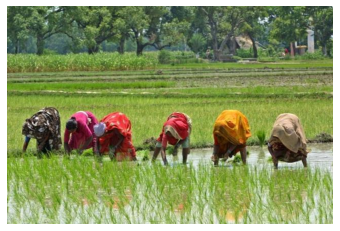

 ফসলের ক্ষেতে কয়েকজন মানুষ কাজ করছে।
1.jpg


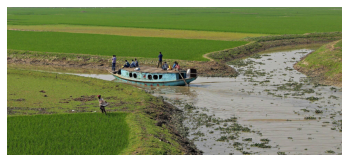

 খাল দিয়ে একটি লঞ্চ যাচ্ছে লঞ্চের উপর কয়েকজন ছেলে বসে আছে ও একজন ক্ষেতে সার দিচ্ছে
10.jpg


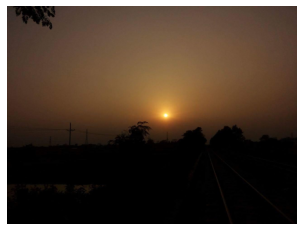

 সূর্য অস্ত যাচ্ছে
11.jpg


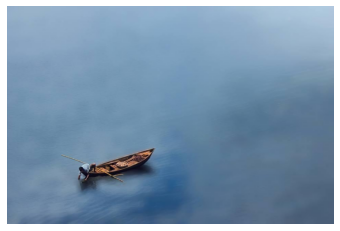

 একজন পুরুষ দুইটি নৌকা চালাচ্ছে।
12.jpg


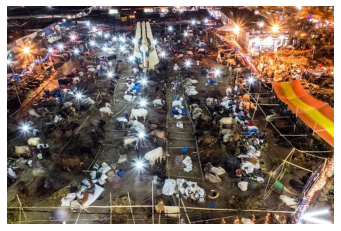

 এটি একটি বাজার।
13.jpg


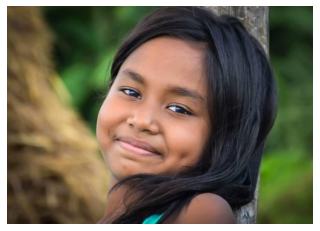

 একজন বাচ্চা মেয়ে মুচকি হাসি দিয়ে আছেন যার চুল লম্বা কালো।
14.jpg


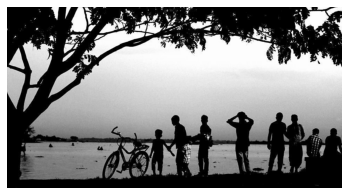

 কয়েকজন মানুষ দাড়িয়ে আছে।
15.jpg


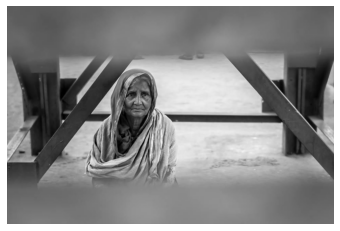

 একজন বৃদ্ধ নারী আছে।
16.jpg


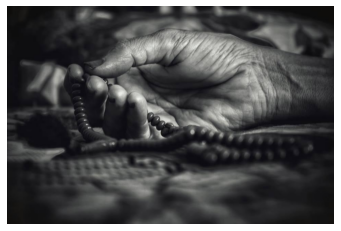

 একটি হাত আছে।
17.jpg


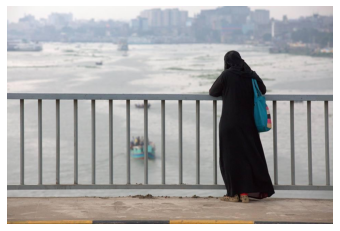

 একজন কালো বোরকা পরা মহিলা একটি রেলিং ধরে দাড়িয়ে আছেন।
18.jpg


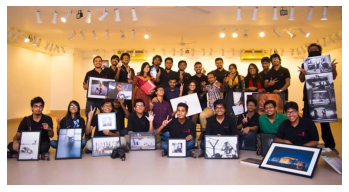

 অনেকগুলো মানুষ আছে।
19.jpg


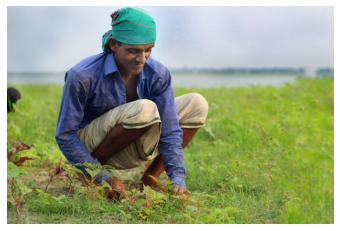

 একজন শার্ট পরা পুরুষ কাজ করছেন।
2.jpg


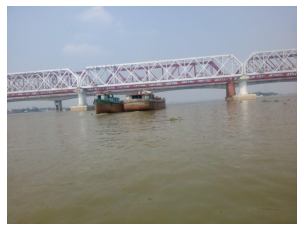

 ব্রীজের নিচ দিয়ে দুইটি লঞ্চ যাচ্ছে
20.jpg


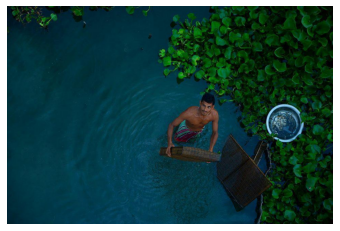

 একজন পুরুষ পানিতে নেমে একটি শিশু পানিতে পাশে
21.jpg


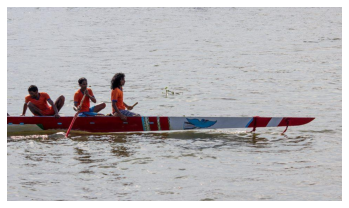

 একটি পাইপের উপর ২ জন মানুষ যারা নেমে বসে আছে এবং পিছনে পাহাড়।
22.jpg


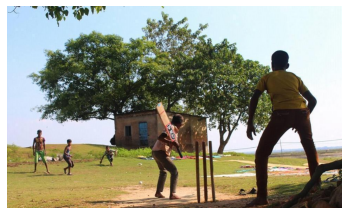

 কিছু ছেলে একটি জমির মাঝে ক্রিকেট খেলছেন।
23.jpg


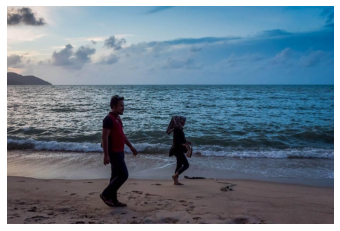

 ১ জন ছেলে এবং একজন মেয়ে সমুদ্র তীরে দাড়িয়ে আছে।
24.jpg


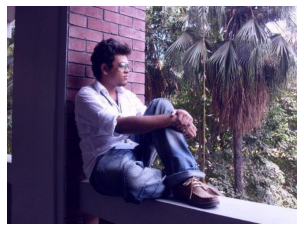

 একজন পুরুষ বসে আছে।
25.jpg


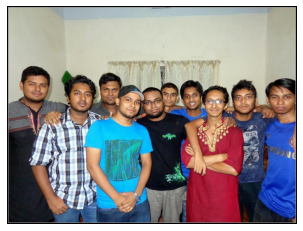

 কিছু ছেলে একসাথেদাড়িয়ে চেয়ে আছে।
26.jpg


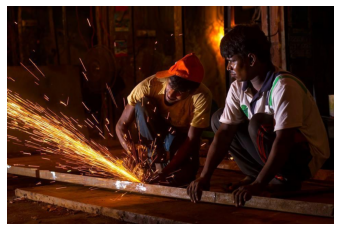

 কয়েকজন মানুষ কাজ করছে।
27.jpg


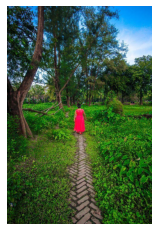

 একটি সবুজ ইটের রাস্তা দিয়ে হেটে যাচ্ছেন একজন গোলাপি কাপড় পরা মেয়ে।
28.jpg


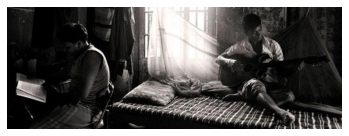

 একটি ছেলে বিছানার উপর বসে গিটার বাজাচ্ছে আর একটি ছেলে চেয়ারে বসে পড়ছে।
29.jpg


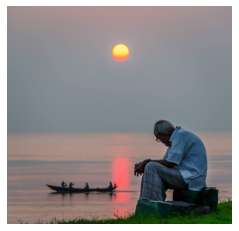

 একজন পুরুষ বসে আছে। দূরে নৌকায় মানুষ আছে।
3.jpg


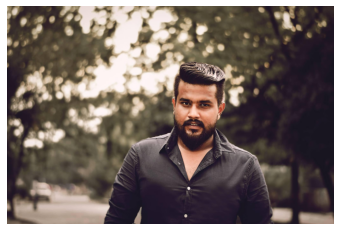

 একজন পুরুষ দাড়িয়ে আছে।
30.jpg


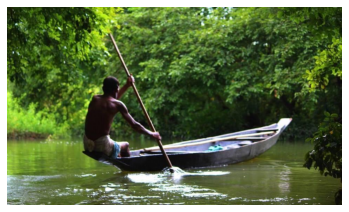

 গাছের নীচ দিয়ে খালের উপরনৌকা চালিয়ে যাচ্ছেন একজন পুরুষ।
31.jpg


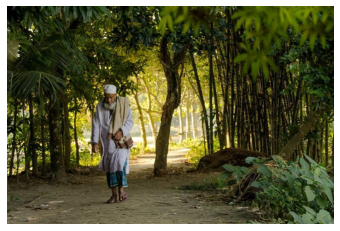

 একজন পুরুষ হেঁটে আসছে।
32.jpg


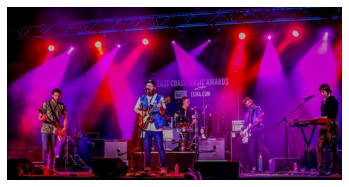

 কয়েকজন মানুষ একটি মঞ্চে বন্ধু
33.jpg


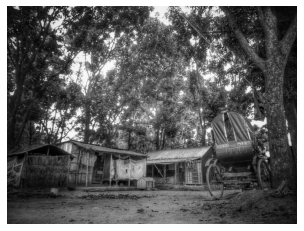

 একটি রিক্সা ও তিনটি রিক্সা আছে।
34.jpg


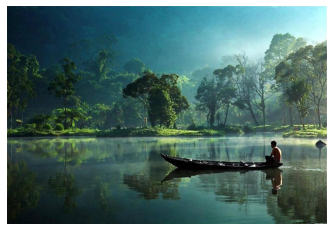

 একজন পুরুষ বসে একটি নৌকা চালাচ্ছেন।
35.jpg


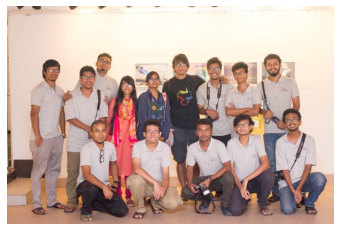

 কিছু ছেলেমেয়ে একসাথে বসে এবং দাড়িয়ে চেয়ে আছেন সামনে।
36.jpg


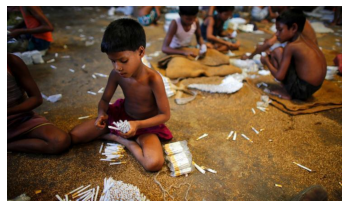

 কয়েকজন মানুষ আছে। পিছনে অনেকগুলো মানুষ আছে।
37.jpg


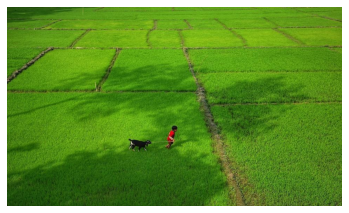

 সবুজ চারা ধান গাছের মাঝে দিয়ে একটি কালো ছাগলের দরি ধরে হেটে যাচ্ছে একটি ছোট ছেলে।
38.jpg


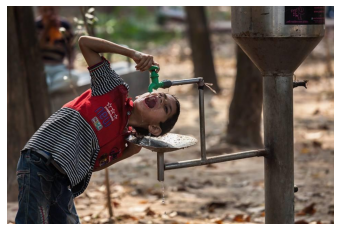

 একটি শিশু আছে।
39.jpg


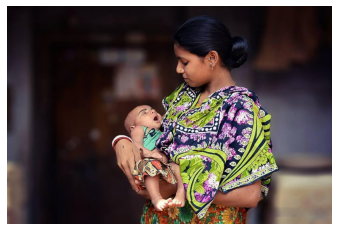

 একজন মহিলা একটি বাচ্চা মেয়ের পাড় দিয়ে দাড়িয়ে আছে।
4.jpg


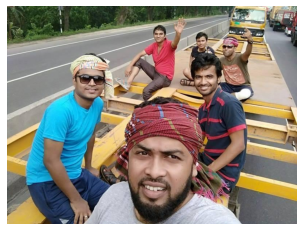

 কয়েকজন ছেলে বাসের উপর চড়ে যাচ্ছে
40.jpg


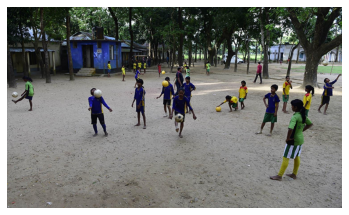

 কিছু বাচ্চা হাতে বাঁশের ঠেলা নিয়ে পানিতে ভিজে আছেন এবং পিছনে রাস্তার পাশ দিয়ে হেটে যাচ্ছে কুলে রাখা আছে।
41.jpg


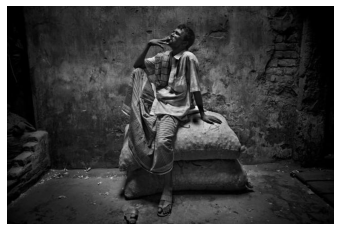

 একজন পুরুষ গুদাম ঘরে২ টি বস্তার উপরে বসে লুঙ্গী শার্ট পরে একটি কাঁদে একটি গামছা দিয়ে তাকিয়ে আছে।
42.jpg


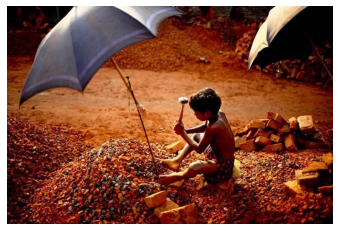

 একটি মেয়ে শিশু দাড়িয়ে আছে। তাদের সামনে একটি ইটের ঝুলে আছে।
43.jpg


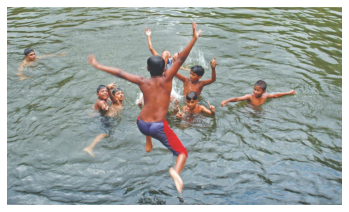

 একটি বড় গরু ভিজা ধান কাজ করছে এবং একটি কালো কাপড় পরা ।
44.jpg


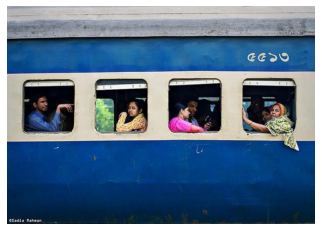

 একজন পুরুষ মানুষ ছবি তুলছে।
45.jpg


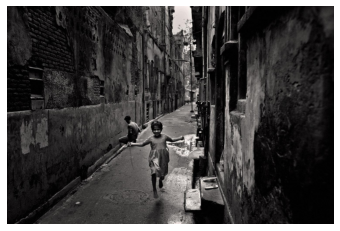

 চাপা গলির ভিতর একজন শিশু খেলছে।
46.jpg


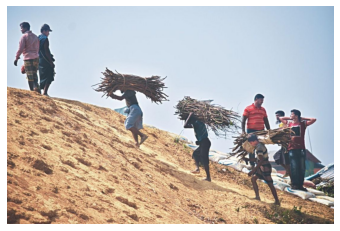

 একটি লোক অনেক গুলো উপর পাড়ে এবং পিছনে কয়েকটা ট্রেন থেকে একটি ট্রেন নিয়ে যাচ্ছে
47.jpg


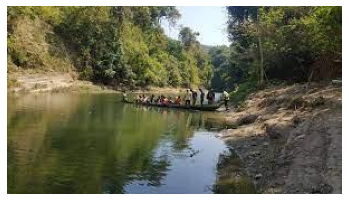

 একজন পুরুষ ২ টি গরু নিয়ে উপরে কাজ করছেন।
48.jpg


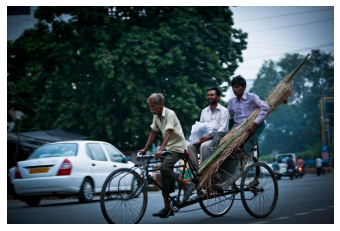

 একটি সেতু আছে।
49.jpg


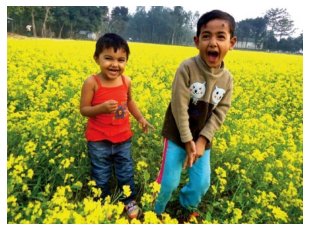

 একটি মহিলা বসে ঝুড়িতে হাতে লাল-সবুজ মহিলা হাতে ধান নিয়ে যাচ্ছে
5.jpg


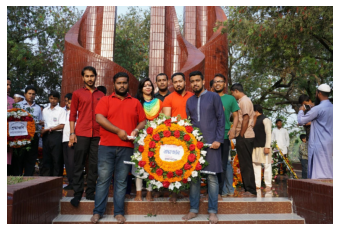

 শহীদ মিনারে অনেক লোকজন ফুলের তোরা হাতে নিয়ে দাড়িয়ে আছে
50.jpg


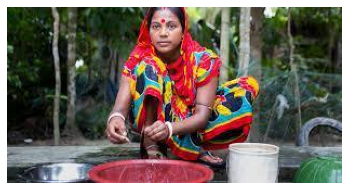

 একটি মেয়ে শিশু আছে।
51.jpg


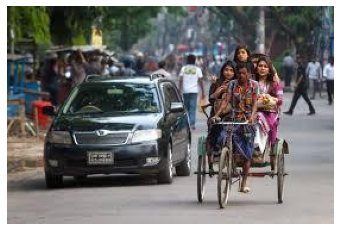

 একটি রিক্সা দিয়ে আসছে ৩ জন মেয়ে এবং রিক্সা চালক টা চালাচ্ছে পাশে একটি কালো গাড়ি।
52.jpg


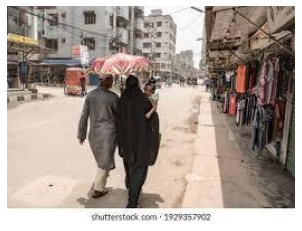

 জলাশয়ে শিশু আছে একটি শিশু দাড়িয়ে আছে।
53.jpg


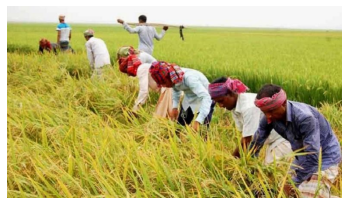

 সরিষা ক্ষেতের মাঝে দুইটি মেয়ে শিশু দাড়িয়ে আছে।
54.jpg


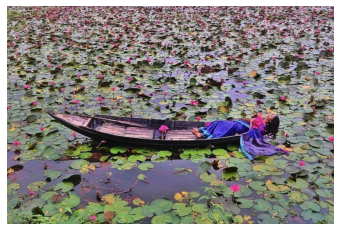

 তিনটি শিশু আছে।
55.jpg


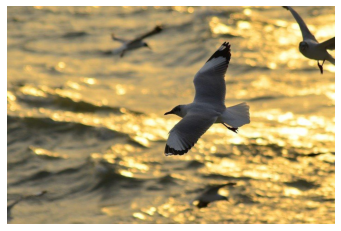

 ফুলের বাগানে একটি শিশু দুই একটি কুকুর কোলে নিয়ে আছে।
56.jpg


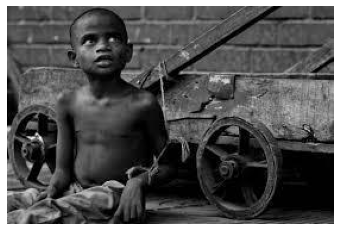

 শার্ট, প্যান্ট পরা একজন লোক হাতে একটা আয়না বানাচ্ছে
57.jpg


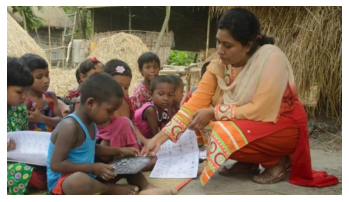

 দুইজন নারী ও একজন পুরুষ পাশাপাশি দাড়িয়ে আছে।
58.jpg


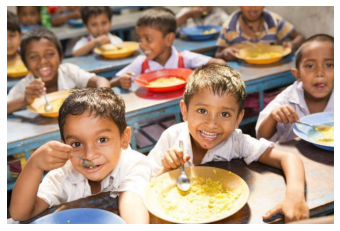

 একজন নারী ও কয়েকজন পুরুষ আছে।
59.jpg


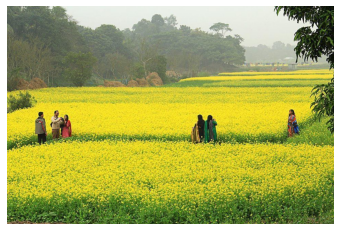

 সরিষা চারজন নারী ও দুইজন পুরুষ আছে।
6.jpg


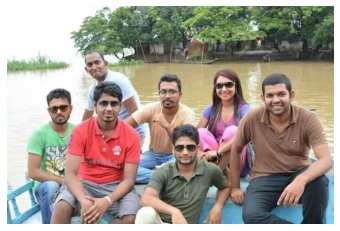

 কয়েকজন ছেলে ও একজন মহিলা দাড়িয়ে আছে
60.jpg


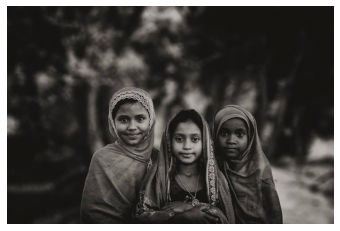

 তিন জন বাচ্চা মেয়ে হিজব পরে দাড়িয়ে চেয়ে আছেন।
61.jpg


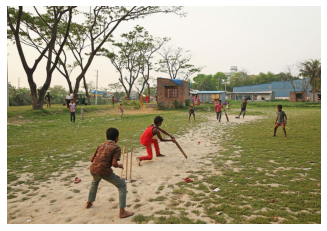

 রেল লাইনের পাশে অনেকগুলো মানুষ আছে।
62.jpg


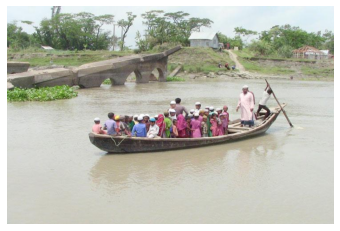

 নদী দিয়ে নদী কয়েকজন মহিলা বসে আছে
63.jpg


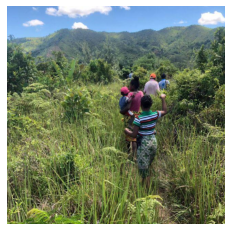

 জমিতে ২ টি গরু নিয়ে হাল চাষ করছে একজন পুরুষ এবং জমিতে ।
64.jpg


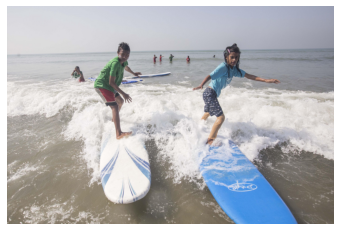

 নদীতে দুইটা নৌকা গোসল করছে আর পাড়ে অনেক মানুষ গোসল করছে
65.jpg


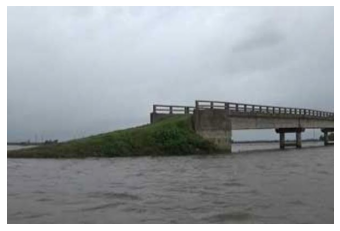

 একটি নৌকায় কয়েকজন মানুষ আছে
66.jpg


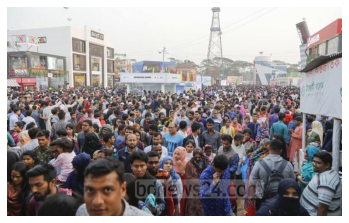

 ৭ জন গুলো মহিলা কাঁধে হাত দিয়ে দাড়িয়ে আছে
67.jpg


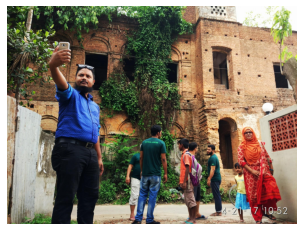

 একটি লোক মোবাইল দিয়ে সেলফি তুলছে ও কয়েকজন ছেলে দাড়িয়ে আছে একজন মহিলা দাড়িয়ে আছে
68.jpg


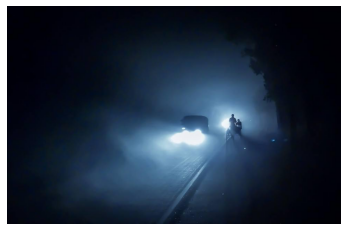

 কুয়াশাছন্ন একটি রাস্তা দিয়ে ব্যান নিয়ে হাত তুলে মানুষ।
69.jpg


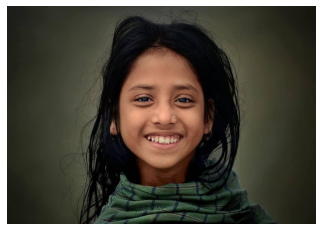

 একটি ছোট মেয়ে লম্বা কালো চুল হাসি মুখে হাসি মুখে দাড়িয়ে আছেন।
7.jpg


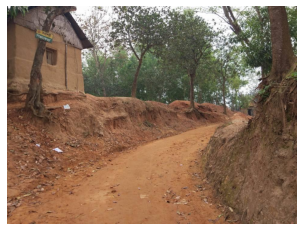

 একজন বালক পানিতে আছে
70.jpg


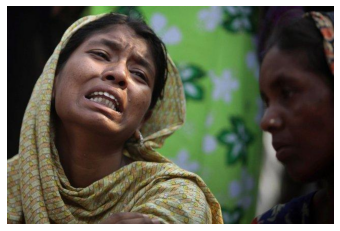

 একটি মহিলা উরনা মাথায় গায়ে পরে কাঁদছে দাঁত বের করে তার চুল কালো তার পিছনে আরেকজন মহিলার মুখ দেখা যায় শারি পরে আছে।
71.jpg


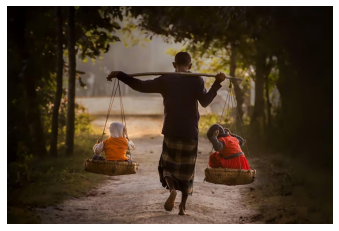

 দুইজন মানুষ আছে।
72.jpg


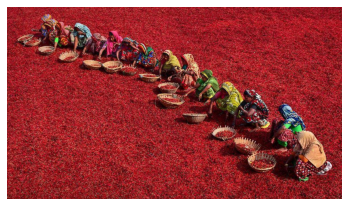

 ১৫ জন মহিলা লাইন ধরে বসে সামনে একটি হাড়ি ধরে নিয়ে এবং মহিলা তাদের হাড়ি ধরে বসে আছে।
73.jpg


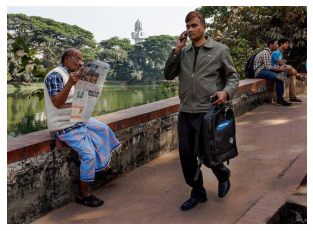

 তিনজন মানুষ বসে আছে ও একজন মানুষ হাঁটছে।
74.jpg


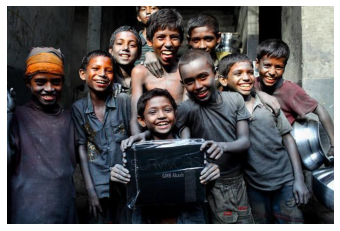

 অনেকগুলো বালক হাসি মুখে দাড়িয়ে আছে।
75.jpg


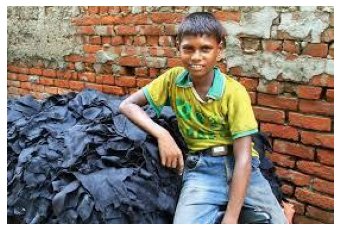

 হলুদ জামা পরিহিত একজন মানুষ বসে আছে।
76.jpg


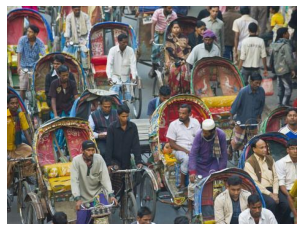

 রাস্তায় অনেকগুলো রিক্সা ও অনেক মানুষ আছে।
77.jpg


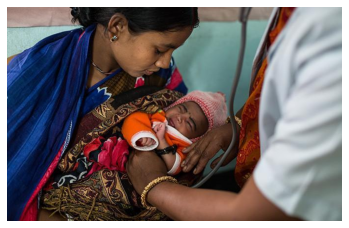

 একজন নারী একটি নবজাতক শিশু কোলে নিয়ে আছে।
8.jpg


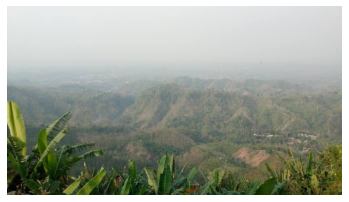

 দূরে পাহাড় দেখা যাচ্ছে
9.jpg


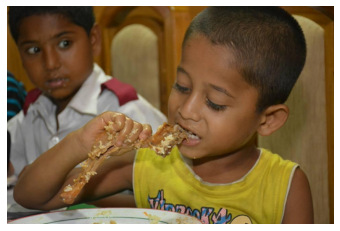

 দুইজন বাচ্চা ছেলে খাবার খাচ্ছে


In [9]:
MAX_LEN=39

images2 = glob('../Data/test/rename/'+'*.jpg')

gen_captions = []

for img_path in images2:
    
   
    test_feature = extractor.predict(getImg(img_path)).reshape(1,2048)
    
    test_img_path = img_path
    test_img = cv2.imread(test_img_path)
    test_img = cv2.cvtColor(test_img, cv2.COLOR_BGR2RGB)
    test_img_name = img_path.split('\\')[-1]
    print(test_img_name)
    plt.imshow(test_img)
    plt.axis('off')
    plt.show()

    text_inp = ['startofseq']

    count = 0
    caption = ''
    while count < 25:
        count += 1

        encoded = []
        for i in text_inp:
            encoded.append(word_count[i])

        encoded = [encoded]

        encoded = pad_sequences(encoded, padding='post', truncating='post', maxlen=MAX_LEN)


        prediction = np.argmax(model.predict([test_feature, encoded]))

        sampled_word = inv_dict[str(prediction)]

        
            
        if sampled_word == 'endofseq':
            break
        else:
            caption = caption + ' ' + sampled_word

        text_inp.append(sampled_word)
    

    

    print(caption)
    gen_captions.append(caption.strip())

In [10]:
textfile = open("../Logs/Xception_BNG9k/Xception_captions.txt", "w",encoding='utf-8')
for element in gen_captions:
    textfile.write(element + "\n")
textfile.close()